# 04 · Which regions and which cell types carry mixed vs factorised codes?

**Question 3 (regions & cell types).** *Where in the brain do we find mostly mixed vs mostly disentangled
representations, and when selectivity is mixed, which cell types from which regions are involved?*

Empirically, nonlinear mixed selectivity is most prominent in association cortex (PFC, PPC) and the
hippocampal formation, whereas early sensory areas and entorhinal grid modules look more factorised
(Rigotti 2013; Bernardi 2020; Whittington 2023 review). We ask whether this pattern **emerges** in a
multi-region RNN from wiring + task demands alone.

**Model** (`mixdis.rnn`): sensory regions S1 (factor A) and S2 (factor B) → association region P
(context input, read-out), optional feedback P→S1,S2. Each region has **fast** (τ = 20 ms) and **slow**
(τ = 200 ms) rate units; optional Dale's law (E/I). Trials: fixation | stimulus | **delay** | response.

Comparisons: linear-only tasks vs + nonlinear tasks; feedback on/off; Dale on/off.

In [1]:
import os, sys, json, time
import numpy as np
import torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(".."))
from mixdis import data, models, metrics, dendrite, rnn
from mixdis.utils import save_json, load_json, set_threads

# FAST=1 -> tiny smoke-test run (minutes). Unset/0 -> full experiment.
FAST = os.environ.get("FAST", "0") == "1"
set_threads()
RES = os.path.abspath("../results"); os.makedirs(RES, exist_ok=True)
FIG = os.path.join(RES, "figures"); os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
def savefig(name):
    plt.savefig(os.path.join(FIG, name + ".png"), bbox_inches="tight", dpi=200)
    plt.savefig(os.path.join(FIG, name + ".pdf"), bbox_inches="tight")
print("FAST mode:", FAST, "| torch", torch.__version__, "| threads", torch.get_num_threads())

FAST mode: False | torch 2.14.1 | threads 7


In [2]:
STEPS = 150 if FAST else 3000
SEEDS = [0] if FAST else [0, 1, 2]
NREG = 32 if FAST else 64
NPER = 8 if FAST else 30
CONFIGS = {"linear tasks, fb": dict(n_nonlinear=0, feedback=True, dale=False),
           "+nonlinear tasks, fb": dict(n_nonlinear=4, feedback=True, dale=False),
           "+nonlinear tasks, no fb": dict(n_nonlinear=4, feedback=False, dale=False),
           "+nonlinear tasks, fb, Dale": dict(n_nonlinear=4, feedback=True, dale=True)}
if FAST:
    CONFIGS = {k: CONFIGS[k] for k in list(CONFIGS)[:2]}
REG = ["S1", "S2", "P"]

def analyse(model, trials, R, C):
    Tf, Ts, Td, Tr = trials.T
    epochs = {"stimulus": slice(Tf, Tf + Ts), "delay": slice(Tf + Ts + Td // 2, Tf + Ts + Td), "response": slice(Tf + Ts + Td, None)}
    out = {}
    slow = model.is_slow.numpy(); region = model.region.numpy()
    for ep, sl in epochs.items():
        Z = R[sl].mean(0)
        cls, nms, _ = metrics.selectivity_discrete(Z, C)
        for r in range(3):
            for typ, tm in [("fast", ~slow), ("slow", slow)]:
                idx = (region == r) & tm
                sel = cls[idx]; resp = sel != "unselective"
                out[(ep, REG[r], typ)] = dict(
                    frac_nms=float(np.mean(sel[resp] == "nonlinear_mixed")) if resp.any() else np.nan,
                    frac_pure=float(np.mean(sel[resp] == "pure")) if resp.any() else np.nan,
                    frac_resp=float(resp.mean()), nms=float(np.nanmean(nms[idx])) if np.isfinite(nms[idx]).any() else np.nan,
                    disent=metrics.disentanglement(Z[:, idx], C.astype(float), deg=2)[0],
                    decA=metrics_decode(Z[:, idx], C[:, 0]), decB=metrics_decode(Z[:, idx], C[:, 1]),
                    decX=metrics_decode(Z[:, idx], C[:, 2]))
    return out

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
def metrics_decode(Z, y):
    if Z.std() < 1e-6: return 1.0 / len(np.unique(y))
    return float(cross_val_score(LogisticRegression(max_iter=2000), Z, y, cv=3).mean())

In [3]:
RES4 = {}
for nm, cfg in CONFIGS.items():
    for seed in SEEDS:
        tr = rnn.Trials(levels=(3, 3, 2), n_nonlinear=cfg["n_nonlinear"], seed=seed)
        m = rnn.MultiRegionRNN(tr.D_stim, tr.nX + 1, tr.n_out, n_per_region=NREG, feedback=cfg["feedback"],
                               dale=cfg["dale"], seed=seed)
        rnn.train_rnn(m, tr, steps=STEPS, batch=128, verbose=False, seed=seed)
        R, C, acc = rnn.collect(m, tr, n_per_cond=NPER)
        RES4[(nm, seed)] = dict(acc=acc, names=tr.task_names, A=analyse(m, tr, R, C))
        print(f"{nm:28s} s{seed}: per-task acc {np.round(acc, 2)}")

linear tasks, fb             s0: per-task acc [1. 1. 1.]
linear tasks, fb             s1: per-task acc [1. 1. 1.]
linear tasks, fb             s2: per-task acc [1. 1. 1.]
+nonlinear tasks, fb         s0: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, fb         s1: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, fb         s2: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, no fb      s0: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, no fb      s1: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, no fb      s2: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, fb, Dale   s0: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, fb, Dale   s1: per-task acc [1. 1. 1. 1. 1. 1. 1.]
+nonlinear tasks, fb, Dale   s2: per-task acc [1. 1. 1. 1. 1. 1. 1.]


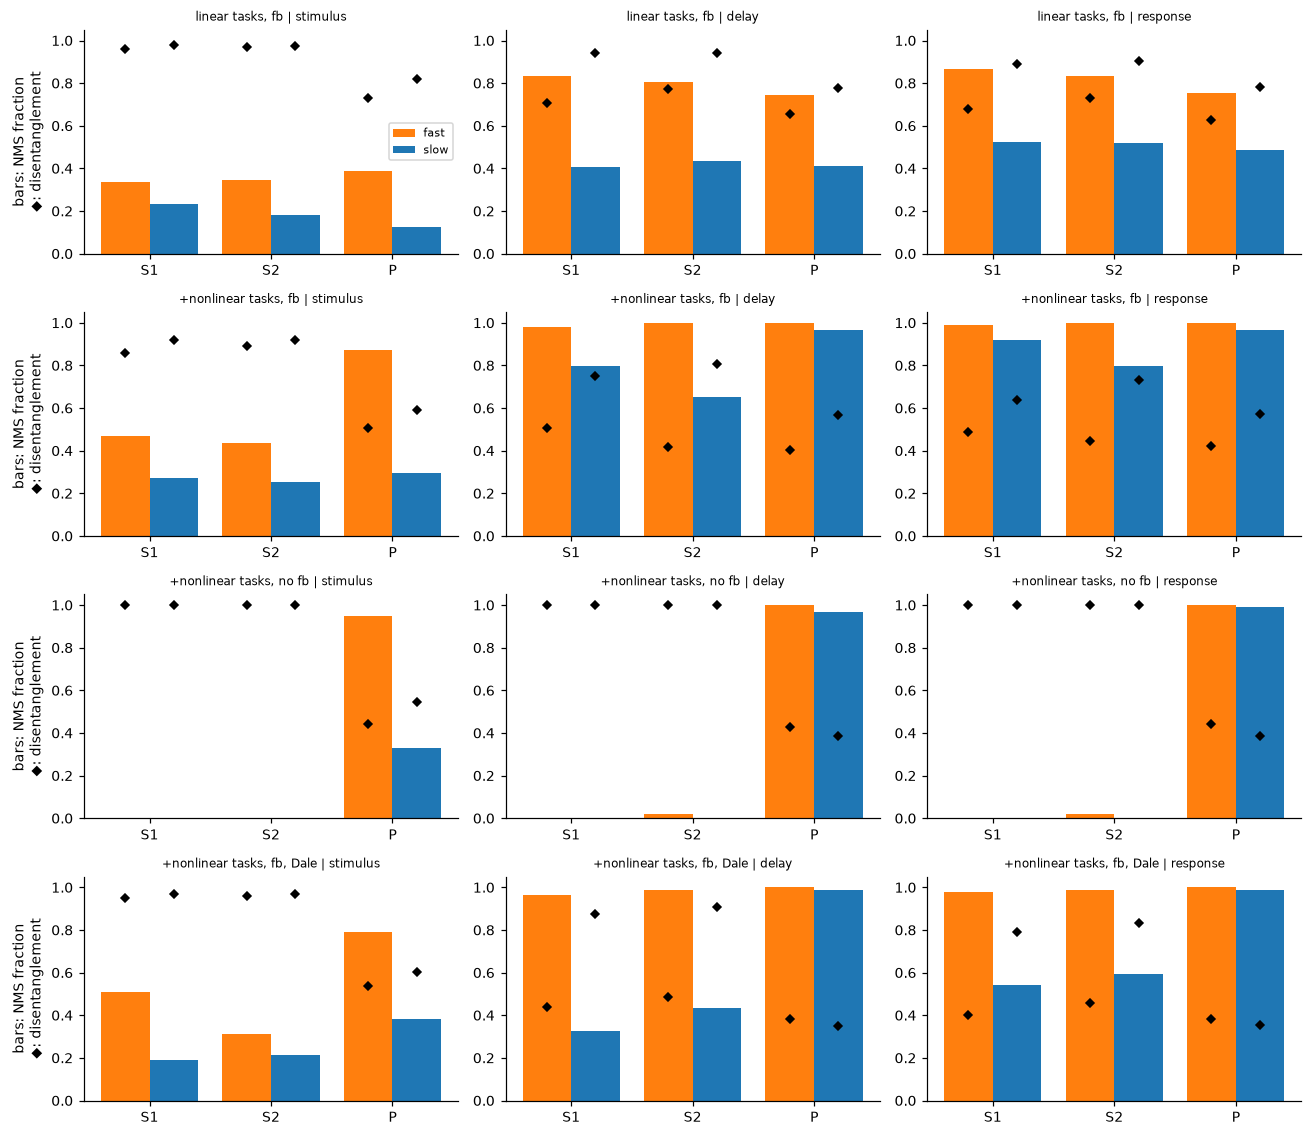

In [4]:
def agg(nm, ep, reg, typ, key):
    return np.nanmean([RES4[(nm, s)]["A"][(ep, reg, typ)][key] for s in SEEDS])
fig, axs = plt.subplots(len(CONFIGS), 3, figsize=(12, 2.6 * len(CONFIGS)), squeeze=False)
for i, nm in enumerate(CONFIGS):
    for j, ep in enumerate(["stimulus", "delay", "response"]):
        ax = axs[i, j]; x = np.arange(3)
        for k, (typ, c) in enumerate([("fast", "tab:orange"), ("slow", "tab:blue")]):
            ax.bar(x + 0.2 * (2 * k - 1), [agg(nm, ep, r, typ, "frac_nms") for r in REG], 0.4, color=c, label=typ)
            ax.plot(x + 0.2 * (2 * k - 1), [agg(nm, ep, r, typ, "disent") for r in REG], "kD", ms=4)
        ax.set_xticks(x); ax.set_xticklabels(REG); ax.set_ylim(0, 1.05)
        ax.set_title(f"{nm} | {ep}", fontsize=8)
    axs[i, 0].set_ylabel("bars: NMS fraction\n◆: disentanglement")
axs[0, 0].legend(fontsize=7); plt.tight_layout(); savefig("04_regions_celltypes_nms"); plt.show()

**Result (3 seeds, all tasks solved at 100 %).** Fraction of responsive units that are nonlinearly mixed, delay epoch
(disentanglement in brackets):

| configuration | S1 fast | S1 slow | S2 fast | S2 slow | P fast | P slow |
|---|---|---|---|---|---|---|
| nonlinear tasks, **no feedback** | 0.00 (1.00) | 0.00 (1.00) | 0.02 (1.00) | 0.00 (1.00) | 1.00 (0.43) | 0.97 (0.38) |
| nonlinear tasks, feedback | 0.98 (0.51) | 0.80 (0.75) | 1.00 (0.42) | 0.65 (0.81) | 1.00 (0.41) | 0.97 (0.57) |
| nonlinear tasks, feedback, Dale | 0.97 (0.44) | 0.33 (0.88) | 0.99 (0.49) | 0.44 (0.91) | 1.00 (0.38) | 0.99 (0.35) |
| linear tasks, feedback | 0.83 (0.71) | 0.41 (0.94) | 0.81 (0.77) | 0.43 (0.94) | 0.74 (0.66) | 0.41 (0.78) |

* Without feedback, sensory regions are perfectly factorised and only the association region mixes: the sensory → association gradient
  of mixed selectivity emerges from wiring alone.
* With feedback, sensory regions become mixed, but mostly **after the stimulus**: during the stimulus epoch the sensory NMS fraction is
  only 0.25–0.47 (vs 0.65–1.00 in the delay). Prediction: mixed selectivity in sensory cortex should appear late and depend on feedback.
* **Slow units stay more factorised than fast units** in sensory regions in every configuration with feedback (most strongly with Dale's law:
  0.33–0.44 vs 0.97–0.99). Even with linear tasks, feedback plus recurrence mixes fast sensory units (0.81–0.83).

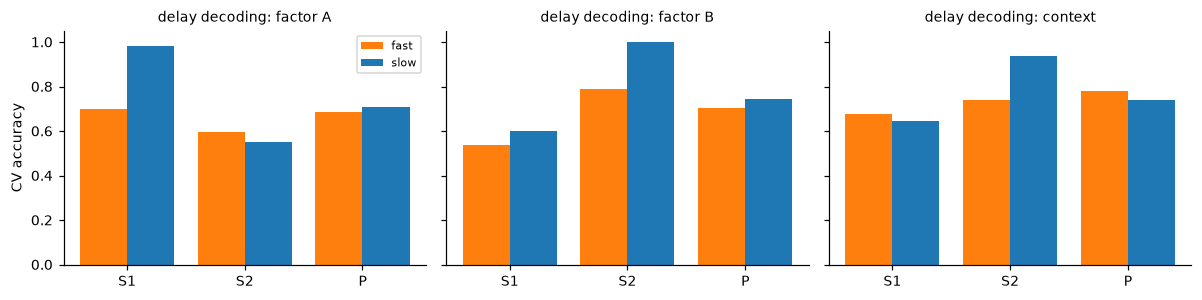

saved


In [5]:
# Memory in the delay: which cell type of which region keeps which factor?
nm = list(CONFIGS)[1]
fig, axs = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for ax, key, t in zip(axs, ["decA", "decB", "decX"], ["factor A", "factor B", "context"]):
    for k, (typ, c) in enumerate([("fast", "tab:orange"), ("slow", "tab:blue")]):
        ax.bar(np.arange(3) + 0.2 * (2 * k - 1), [agg(nm, "delay", r, typ, key) for r in REG], 0.4, color=c, label=typ)
    ax.set_xticks(range(3)); ax.set_xticklabels(REG); ax.set_title(f"delay decoding: {t}", fontsize=9)
axs[0].set_ylabel("CV accuracy"); axs[0].legend(fontsize=7); plt.tight_layout(); savefig("04_delay_memory_by_type"); plt.show()
save_json({"|".join(map(str, k)): {"acc": v["acc"], "names": v["names"],
                                   "A": {"|".join(kk): vv for kk, vv in v["A"].items()}} for k, v in RES4.items()},
          os.path.join(RES, "nb04_regions_celltypes.json")); print("saved")

**Result.** Slow sensory units are the delay-period memory of their own factor (decoding of A from S1-slow 0.98–1.00 vs S1-fast 0.70–0.91;
B from S2-slow 1.00 vs S2-fast 0.72–0.79). Sensory units carry little *linear* information about the other region's factor
(0.46–0.60, chance 0.33), so the mixing of fast sensory units reflects nonlinear, context-dependent modulation of their own factor by
feedback rather than a copy of the other factor. Answer to "which cell types are involved when selectivity is mixed?": here, the
**fast** units of every region and both unit types of the association region.

### Summary of notebook 04
* A sensory → association gradient of mixed selectivity emerges from wiring: without feedback, sensory regions are pure (NMS 0.00) and the
  association region is mixed (0.97–1.00).
* Feedback makes sensory regions mixed late in the trial (delay/response), not during the stimulus.
* Cell types divide the work: slow units hold their own factor in memory and stay factorised; fast units mix, especially in sensory regions.
* Caveats: Dale's-law analyses pool excitatory and inhibitory units (split them next); time constants are fixed by design, not learned.